# **What is Pandas & Why It Matters**

Pandas is Python's core library for working with tabular data (rows and columns, like a spreadsheet or SQL table).

Built on top of NumPy, so it's fast for numerical operations.
The backbone of almost every data preprocessing pipeline in Python.
Used before feeding data into ML libraries (scikit-learn, PyTorch, TensorFlow).

In [ ]:
import pandas as pd
import numpy as np

*Convention: always import pandas as pd.*

# Core Data Structures
**Series (1-dimensional)**

A Series is a labeled 1D array — like a single column.

In [ ]:
s = pd.Series([10, 20, 30, 40], index=['a', 'b', 'c', 'd'])
print(s)

a    10
b    20
c    30
d    40
dtype: int64


**DataFrame (2-dimensional)**

A DataFrame is a table — a collection of Series sharing the same index.

In [ ]:
data = {
    'name': ['Ali', 'Sara', 'Omar'],
    'age': [25, 30, 22],
    'city': ['Karachi', 'Lahore', 'Islamabad']
}
df = pd.DataFrame(data)
print(df)

*Key concepts:*

df.index → row labels

df.columns → column labels

df.values → underlying NumPy array

# Reading & Writing Data
This is usually step 1 in any preprocessing project.

In [ ]:
# Reading
df = pd.read_csv('data.csv')
df = pd.read_excel('data.xlsx', sheet_name='Sheet1')
df = pd.read_json('data.json')
df = pd.read_sql('SELECT * FROM table', connection)

# Writing
df.to_csv('output.csv', index=False)
df.to_excel('output.xlsx', index=False)
df.to_json('output.json')

***Useful read_csv parameters for messy real-world data:***

In [ ]:
pd.read_csv(
    'data.csv',
    sep=',',              # delimiter
    header=0,              # which row is the header
    na_values=['NA', '?', 'missing'],  # custom null markers
    dtype={'id': str},     # force column types
    parse_dates=['date'],  # auto-parse date columns
    encoding='utf-8'
)

# Inspecting Data
Always inspect before you clean.

In [ ]:
df.head()          # first 5 rows
df.tail(10)         # last 10 rows
df.shape            # (rows, columns)
df.info()           # dtypes, non-null counts, memory
df.describe()        # summary stats for numeric columns
df.describe(include='object')  # summary for categorical columns
df.columns          # column names
df.dtypes            # data types per column
df.nunique()          # unique value count per column
df['col'].value_counts()   # frequency table
df.isnull().sum()     # missing values per column

**Habit to build:**

Run df.info() and df.isnull().sum() on every new dataset before doing anything else.

# Selecting & Indexing Data
Three main ways to select data:

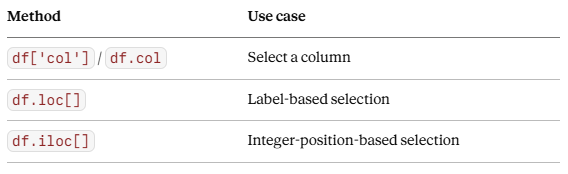

In [ ]:
df['age']                 # single column -> Series
df[['name', 'age']]        # multiple columns -> DataFrame

df.loc[0]                 # row with label/index 0
df.loc[0:2, ['name','age']]  # rows 0-2, specific columns (inclusive!)

df.iloc[0]                 # first row by position
df.iloc[0:2, 0:2]           # first 2 rows, first 2 columns (exclusive end)

df.at[0, 'name']            # fast scalar access (label-based)
df.iat[0, 0]                # fast scalar access (position-based)

# Filtering Data (Boolean Indexing)
This is one of the most-used preprocessing tools.

In [ ]:
df[df['age'] > 25]

df[(df['age'] > 25) & (df['city'] == 'Lahore')]   # AND -> use &
df[(df['age'] > 25) | (df['city'] == 'Lahore')]   # OR  -> use |
df[~(df['age'] > 25)]                              # NOT -> use ~

df[df['city'].isin(['Lahore', 'Karachi'])]
df[df['name'].str.contains('Ali', na=False)]

df.query('age > 25 and city == "Lahore"')   # alternative readable syntax

# Handling Missing Data
Critical for preprocessing — real data is almost always incomplete

In [ ]:
df.isnull()               # boolean mask of nulls
df.isnull().sum()          # count nulls per column
df.isnull().mean() * 100   # % missing per column

# Dropping
df.dropna()                       # drop rows with ANY null
df.dropna(axis=1)                  # drop columns with ANY null
df.dropna(subset=['age'])          # drop rows where 'age' is null
df.dropna(thresh=3)                # keep rows with at least 3 non-null values

# Filling
df.fillna(0)
df['age'].fillna(df['age'].mean(), inplace=True)
df['city'].fillna(df['city'].mode()[0], inplace=True)
df.fillna(method='ffill')          # forward fill
df.fillna(method='bfill')          # backward fill
df.interpolate()                    # interpolate numeric gaps

**Preprocessing tip:** Decide your missing-data strategy per column, not globally. Numeric → mean/median/interpolate. Categorical → mode or a placeholder like "Unknown". Time series → forward/backward fill.

# Data Types & Type Conversion
Wrong dtypes silently break analysis and models.

In [ ]:
df.dtypes

df['age'] = df['age'].astype(int)
df['price'] = df['price'].astype(float)
df['category'] = df['category'].astype('category')   # saves memory, speeds up groupby
df['id'] = df['id'].astype(str)

pd.to_numeric(df['col'], errors='coerce')   # invalid parsing -> NaN
pd.to_datetime(df['date'], errors='coerce')

*errors='coerce'* is extremely useful in preprocessing: it turns unparseable values into NaN instead of crashing your pipeline.

# String Operations
Accessed via the .str accessor — essential for cleaning text columns.

In [ ]:
df['name'] = df['name'].str.strip()          # remove whitespace
df['name'] = df['name'].str.lower()           # lowercase
df['name'] = df['name'].str.title()            # title case
df['name'] = df['name'].str.replace('_', ' ')

df['email'].str.contains('@gmail.com', na=False)
df['email'].str.split('@').str[0]              # get username part
df['phone'].str.extract(r'(\d{3})-(\d{4})')     # regex extraction
df['name'].str.len()                            # string length

# Handling Duplicates

In [ ]:
df.duplicated()               # boolean mask
df.duplicated().sum()          # count duplicates
df.drop_duplicates()
df.drop_duplicates(subset=['name', 'city'], keep='first')

# Working with Dates & Times

In [ ]:
df['date'] = pd.to_datetime(df['date'])

df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['weekday'] = df['date'].dt.day_name()

df.set_index('date', inplace=True)
df.resample('M').sum()          # monthly aggregation
df.resample('W').mean()          # weekly average

(df['end_date'] - df['start_date']).dt.days   # date differences

# A Complete Preprocessing Workflow (Case Study)

A typical end-to-end pipeline you'll repeat constantly:

In [ ]:
# 1. Load
df = pd.read_csv('raw_data.csv')

# 2. Inspect
print(df.info())
print(df.isnull().sum())

# 3. Standardize column names
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_')

# 4. Fix data types
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df['price'] = pd.to_numeric(df['price'], errors='coerce')

# 5. Handle missing values
df['price'].fillna(df['price'].median(), inplace=True)
df.dropna(subset=['id'], inplace=True)

# 6. Remove duplicates
df.drop_duplicates(subset=['id'], inplace=True)

# 7. Handle outliers
df['price'] = df['price'].clip(lower=0, upper=df['price'].quantile(0.99))

# 8. Feature engineering
df['year'] = df['date'].dt.year
df['price_category'] = pd.cut(df['price'], bins=[0, 50, 200, np.inf],
                               labels=['cheap', 'mid', 'expensive'])

# 9. Encode categoricals (for ML)
df = pd.get_dummies(df, columns=['price_category'], drop_first=True)

# 10. Save clean data
df.to_csv('clean_data.csv', index=False)